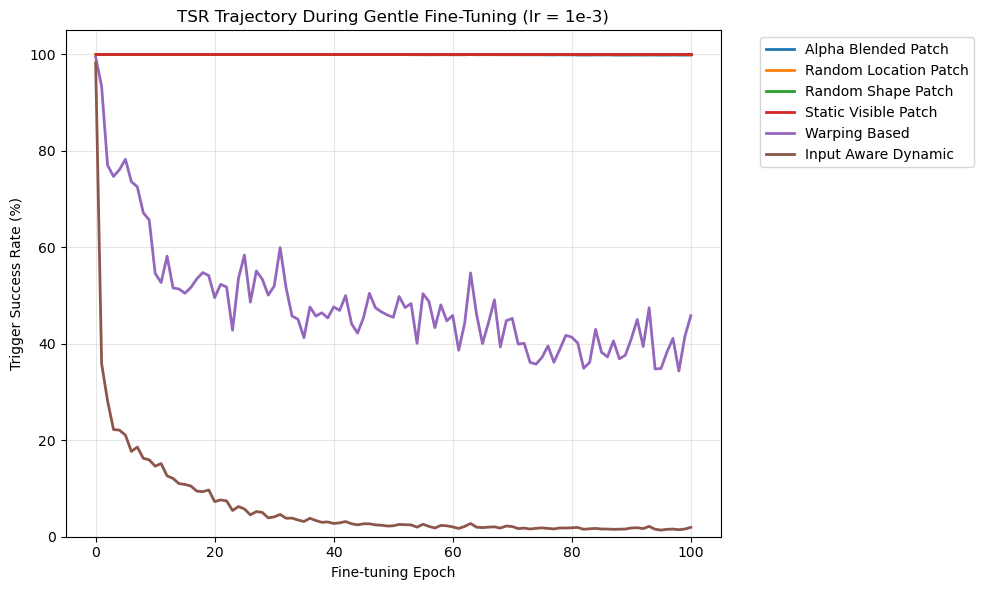

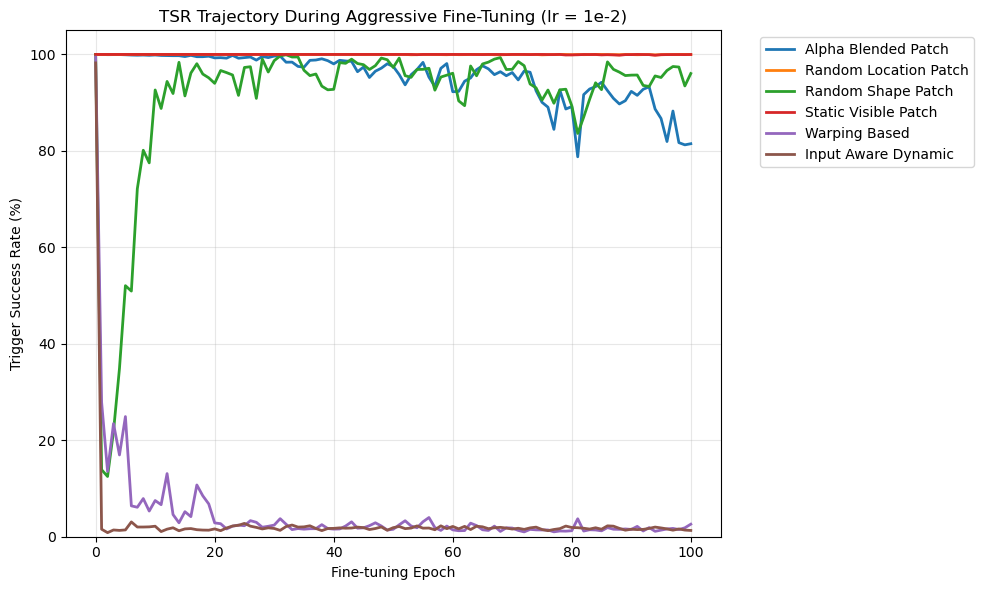

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

gentle_files = {
    "Alpha Blended Patch": Path("patch_trigger/run/finetuning/lr1e-3/ftal_wm_patch_alpha_blended_resnet18_cifar10_lr1e-03.csv"),
    "Random Location Patch": Path("patch_trigger/run/finetuning/lr1e-3/ftal_wm_patch_random_location_resnet18_cifar10_lr1e-03.csv"),
    "Random Shape Patch": Path("patch_trigger/run/finetuning/lr1e-3/ftal_wm_patch_random_shape_resnet18_cifar10_lr1e-03.csv"),
    "Static Visible Patch": Path("patch_trigger/run/finetuning/lr1e-3/ftal_wm_patch_static_visible_resnet18_cifar10_lr1e-03.csv"),
    "Warping Based": Path("warping_based/run/finetuning/lr1e-3/ftal_best_model_lr1e-03.csv"),
    "Input Aware Dynamic": Path("input_aware/run/finetuning/lr1e-3/ftal_best_model_lr1e-03.csv"),
}

aggressive_files = {
    "Alpha Blended Patch": Path("patch_trigger/run/finetuning/lr1e-2/ftal_wm_patch_alpha_blended_resnet18_cifar10_lr1e-02.csv"),
    "Random Location Patch": Path("patch_trigger/run/finetuning/lr1e-2/ftal_wm_patch_random_location_resnet18_cifar10_lr1e-02.csv"),
    "Random Shape Patch": Path("patch_trigger/run/finetuning/lr1e-2/ftal_wm_patch_random_shape_resnet18_cifar10_lr1e-02.csv"),
    "Static Visible Patch": Path("patch_trigger/run/finetuning/lr1e-2/ftal_wm_patch_static_visible_resnet18_cifar10_lr1e-02.csv"),
    "Warping Based": Path("warping_based/run/finetuning/lr1e-2/ftal_best_model_lr1e-02.csv"),
    "Input Aware Dynamic": Path("input_aware/run/finetuning/lr1e-2/ftal_best_model_lr1e-02.csv"),
}

def plot_tsr_curves(file_map, title):
    plt.figure(figsize=(10, 6))

    for label, path in file_map.items():
        df = pd.read_csv(path)

        # Keep only rows with epoch values.
        df = df[pd.to_numeric(df["epoch"], errors="coerce").notna()].copy()
        df["epoch"] = df["epoch"].astype(int)

        plt.plot(
            df["epoch"],
            df["tsr_percent"],
            label=label,
            linewidth=2,
        )

    plt.title(title)
    plt.xlabel("Fine-tuning Epoch")
    plt.ylabel("Trigger Success Rate (%)")
    plt.ylim(0, 105)
    plt.grid(True, alpha=0.3)
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

plot_tsr_curves(
    gentle_files,
    "TSR Trajectory During Gentle Fine-Tuning (lr = 1e-3)",
)

plot_tsr_curves(
    aggressive_files,
    "TSR Trajectory During Aggressive Fine-Tuning (lr = 1e-2)",
)

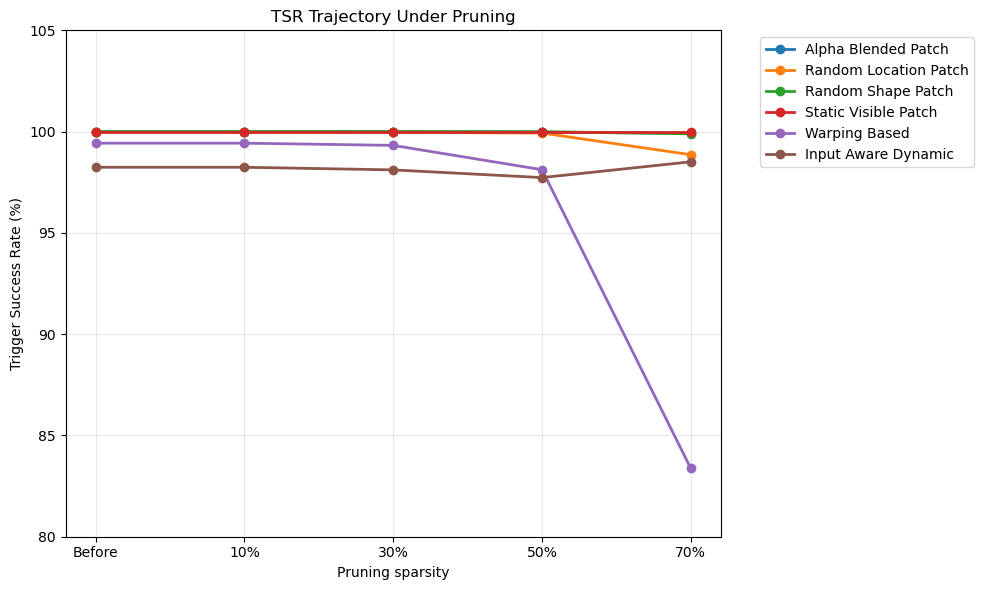

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data = {
    "Watermark Type": [
        "Alpha Blended Patch",
        "Random Location Patch",
        "Random Shape Patch",
        "Static Visible Patch",
        "Warping Based",
        "Input Aware Dynamic",
    ],
    "Before": [100.00, 99.98, 100.00, 100.00, 99.43, 98.24],
    "10%": [100.00, 99.98, 100.00, 100.00, 99.43, 98.24],
    "30%": [100.00, 99.96, 100.00, 100.00, 99.32, 98.11],
    "50%": [99.97, 99.93, 100.00, 100.00, 98.12, 97.73],
    "70%": [99.92, 98.86, 99.89, 100.00, 83.37, 98.51],
}

df = pd.DataFrame(data)

x_labels = ["Before", "10%", "30%", "50%", "70%"]

plt.figure(figsize=(10, 6))

for _, row in df.iterrows():
    plt.plot(
        x_labels,
        [row[label] for label in x_labels],
        marker="o",
        linewidth=2,
        label=row["Watermark Type"],
    )

plt.title("TSR Trajectory Under Pruning")
plt.xlabel("Pruning sparsity")
plt.ylabel("Trigger Success Rate (%)")
plt.ylim(80, 105)
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()